In [25]:
import pickle
import numpy as np

class NumpyCompatUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module.startswith("numpy._core"):
            module = module.replace("numpy._core", "numpy.core")
        return super().find_class(module, name)
if np.__version__ >= '2.0.0':
    with open('train_data.pkl', 'rb') as f:
        data = pickle.load(f)
else:
    with open('train_data.pkl', 'rb') as f:
        data = NumpyCompatUnpickler(f).load()

train_image_embeddings = data['train_image_embeddings']
gender_labels = data['gender_labels']
test_image_embeddings = data['test_image_embeddings']

print('Shape of train_image_embeddings:', train_image_embeddings.shape)
print('Shape of gender_labels:', gender_labels.shape)
print('Shape of test_image_embeddings:', test_image_embeddings.shape)

Shape of train_image_embeddings: (15000, 512)
Shape of gender_labels: (15000,)
Shape of test_image_embeddings: (15000, 512)


In [26]:
X = train_image_embeddings
y = gender_labels
X_final = test_image_embeddings

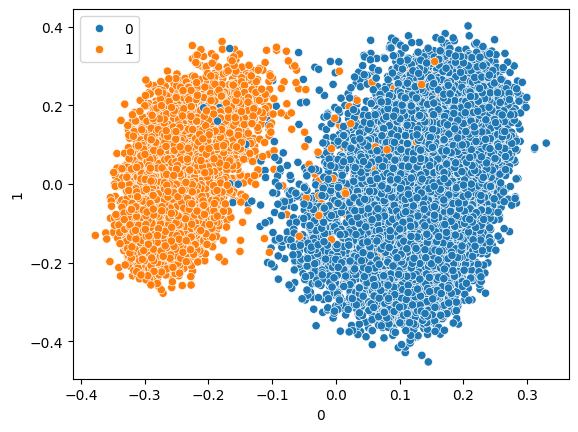

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA

decom = PCA(n_components=2, random_state=42)
X_red = pd.DataFrame(decom.fit_transform(X))

sns.scatterplot(x=X_red[0], y=X_red[1], hue=y)
plt.show()

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import cross_val_score

model = LogisticRegression()

cross_val_score(model, X, y, cv=3, scoring='accuracy').mean()

0.9915333333333334

In [29]:
model.fit(X, y)
y_final = model.predict(X_final)

In [30]:
X0 = X[y == 0]
X1 = X[y == 1]

mean_0 = np.mean(X0, axis=0)
mean_1 = np.mean(X1, axis=0)

debiased_train_image_embeddings = []
for i, vec in enumerate(X):
    label = y[i]
    if label == 0:
        good_vec = vec - mean_0
    if label == 1:
        good_vec = vec - mean_1
    debiased_train_image_embeddings.append(good_vec)

debiased_train_image_embeddings = np.array(debiased_train_image_embeddings)
debiased_train_image_embeddings.shape

(15000, 512)

In [31]:
debiased_test_image_embeddings = []
for i, vec in enumerate(X_final):
    label = y[i]
    if label == 0:
        good_vec = vec - mean_0
    if label == 1:
        good_vec = vec - mean_1
    debiased_test_image_embeddings.append(good_vec)

debiased_test_image_embeddings = np.array(debiased_test_image_embeddings)
debiased_test_image_embeddings.shape

(15000, 512)

In [32]:
def generate_submission(debiased_train_image_embeddings, debiased_test_image_embeddings, compression=data['compression']):
    train_compression = debiased_train_image_embeddings @ compression.T
    test_compression = debiased_test_image_embeddings @ compression.T
    with open('submission.pkl', 'wb') as f:
        pickle.dump({'train_compression': train_compression, 'test_compression': test_compression}, f)
generate_submission(debiased_train_image_embeddings, debiased_test_image_embeddings)